# Spectral Scale Selection for Gaussian KDE

This notebook implements the experiment for samples
$X_1,\dots,X_n \sim N(0,\sigma^2)$ and Gaussian kernel density estimators.

For a bandwidth grid $0<h_1<\dots<h_N$, we build

$$
S_\gamma(\hat f_{h_i},\hat f_{h_j})
=\exp\left(-\gamma\lVert \hat f_{h_i}-\hat f_{h_j}\rVert_2^2\right)
$$

using the exact Gaussian-kernel formula

$$
D_{ij}=I_{ii}+I_{jj}-2I_{ij},\qquad
I_{ij}=\frac{1}{n^2}\frac{1}{\sqrt{2\pi(h_i^2+h_j^2)}}
\sum_{k,l=1}^{n}\exp\left(-\frac{(X_k-X_l)^2}{2(h_i^2+h_j^2)}\right).
$$

The selected spectral bandwidth is the grid point where the Perron vector of $S_\gamma$ is maximal.
Since the true density is known in this simulation, we compare it to the oracle bandwidth

$$
h_{oracle}=\arg\min_{h_i}\int \left(\hat f_{h_i}(x)-f(x)\right)^2\,dx.
$$


In [29]:
from __future__ import annotations

import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".matplotlib-cache"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=4, suppress=True)


## Four similarity matrices used for spectral scale selection

For a bandwidth grid $0<h_1<\dots<h_N$, write
$\hat f_i=\hat f_{h_i}$.
The spectral selector needs a nonnegative similarity matrix, so large entries should mean that two KDEs are close as densities.

In this block the KDEs are evaluated on a one-dimensional quadrature grid $x_1,\dots,x_M$.
All integrals below are then approximated by the trapezoidal rule.
The optional numerical renormalization only corrects the small mass lost because the quadrature grid is finite.

The four implemented similarities are

$$
S^{TV}_{ij}
=1-d_{TV}(\hat f_i,\hat f_j)
=\int \min\{\hat f_i(x),\hat f_j(x)\}\,dx,
$$

$$
S^{H}_{ij}
=\int \sqrt{\hat f_i(x)\hat f_j(x)}\,dx,
$$

$$
S^{\gamma}_{ij}
=\exp\left(-\gamma\lVert \hat f_i-\hat f_j\rVert_2^2\right),
$$

and

$$
S^{JS}_{ij}
=1-\frac{\operatorname{JS}(\hat f_i,\hat f_j)}{\log 2}.
$$

Here

$$
\operatorname{JS}(f,g)
=H\left(\frac{f+g}{2}\right)-\frac12H(f)-\frac12H(g),
\qquad
H(f)=-\int f(x)\log f(x)\,dx.
$$


In [ ]:
def bandwidth_grid_for_gaussian_experiment(
    n: int,
    sigma2: float,
    n_h: int = 80,
    h_min_factor: float = 0.25,
    h_max_factor: float = 2.50,
) -> np.ndarray:
    """Logarithmic bandwidth grid for the Gaussian simulation model."""
    sigma = float(np.sqrt(sigma2))
    center = sigma * n ** (-1 / 5)
    return np.geomspace(h_min_factor * center, h_max_factor * center, int(n_h))


def gaussian_kde_values(samples: np.ndarray, h_grid: np.ndarray, x_grid: np.ndarray) -> np.ndarray:
    """Return KDE values with shape (number of bandwidths, number of x-grid points)."""
    samples = np.asarray(samples, dtype=float)
    h_grid = np.asarray(h_grid, dtype=float)
    x_grid = np.asarray(x_grid, dtype=float)

    z = (x_grid[None, None, :] - samples[None, :, None]) / h_grid[:, None, None]
    kernel_values = np.exp(-0.5 * z**2) / np.sqrt(2 * np.pi)
    return kernel_values.mean(axis=1) / h_grid[:, None]


def quadrature_grid_for_kdes(
    samples: np.ndarray,
    h_grid: np.ndarray,
    sigma2: float | None = None,
    m_x: int = 2_001,
    padding: float = 6.0,
) -> np.ndarray:
    """Build a finite integration grid wide enough for the data and KDE tails."""
    samples = np.asarray(samples, dtype=float)
    h_grid = np.asarray(h_grid, dtype=float)
    empirical_scale = np.std(samples, ddof=1) if len(samples) > 1 else 1.0
    reference_scale = empirical_scale if sigma2 is None else max(empirical_scale, float(np.sqrt(sigma2)))
    radius = padding * (reference_scale + float(np.max(h_grid)))
    left = min(float(np.min(samples)) - radius, -radius)
    right = max(float(np.max(samples)) + radius, radius)
    return np.linspace(left, right, int(m_x))


def normalize_density_rows(values: np.ndarray, x_grid: np.ndarray) -> np.ndarray:
    """Normalize each row so that its trapezoidal integral is one."""
    values = np.asarray(values, dtype=float)
    masses = trapezoidal_integral(values, x_grid, axis=1)
    if np.any(masses <= 0):
        raise ValueError("Every density row must have positive quadrature mass.")
    return values / masses[:, None]


def trapezoidal_integral(values: np.ndarray, x_grid: np.ndarray, axis: int = -1) -> np.ndarray:
    """Version-compatible trapezoidal rule wrapper."""
    trapezoid = getattr(np, "trapezoid", np.trapz)
    return trapezoid(values, x=x_grid, axis=axis)


def perron_vector(matrix: np.ndarray) -> np.ndarray:
    """Principal nonnegative eigenvector, normalized to sum to one."""
    matrix = np.asarray(matrix, dtype=float)
    eigenvalues, eigenvectors = np.linalg.eigh((matrix + matrix.T) / 2)
    vector = np.real(eigenvectors[:, int(np.argmax(eigenvalues))])
    if np.sum(vector) < 0:
        vector = -vector
    vector = np.maximum(vector, 0.0)
    if np.sum(vector) == 0:
        vector = np.abs(np.real(eigenvectors[:, int(np.argmax(eigenvalues))]))
    return vector / np.sum(vector)


def spectral_choice_from_similarity(similarity_matrix: np.ndarray) -> dict[str, np.ndarray | int | float]:
    """Choose the index where the Perron vector of a similarity matrix is maximal."""
    vector = perron_vector(similarity_matrix)
    return {
        "selected_index": int(np.argmax(vector)),
        "perron_vector": vector,
        "selected_weight": float(np.max(vector)),
    }


def _auto_gamma_from_l2_squared(l2_squared: np.ndarray) -> float:
    positive = l2_squared[l2_squared > 0]
    if len(positive) == 0:
        return 1.0
    return float(1.0 / np.median(positive))


def exact_gaussian_kde_l2_gram(samples: np.ndarray, h_grid: np.ndarray) -> np.ndarray:
    """Exact Gram matrix <f_hat_h_i, f_hat_h_j> for one-dimensional Gaussian KDEs."""
    samples = np.asarray(samples, dtype=float)
    h_grid = np.asarray(h_grid, dtype=float)
    n = len(samples)
    squared_differences = (samples[:, None] - samples[None, :]) ** 2
    gram = np.empty((len(h_grid), len(h_grid)), dtype=float)

    for i, h_i in enumerate(h_grid):
        for j, h_j in enumerate(h_grid[i:], start=i):
            variance = h_i**2 + h_j**2
            value = np.exp(-squared_differences / (2 * variance)).sum()
            value /= n**2 * np.sqrt(2 * np.pi * variance)
            gram[i, j] = value
            gram[j, i] = value
    return gram


def exact_oracle_ise_values(samples: np.ndarray, h_grid: np.ndarray, sigma2: float) -> np.ndarray:
    """Exact ISE against the true density N(0, sigma2) for Gaussian KDEs."""
    samples = np.asarray(samples, dtype=float)
    h_grid = np.asarray(h_grid, dtype=float)
    sigma = float(np.sqrt(sigma2))
    n = len(samples)
    squared_differences = (samples[:, None] - samples[None, :]) ** 2

    kde_squared_integral = []
    for h in h_grid:
        variance = 2.0 * h**2
        value = np.exp(-squared_differences / (2 * variance)).sum()
        value /= n**2 * np.sqrt(2 * np.pi * variance)
        kde_squared_integral.append(value)
    kde_squared_integral = np.asarray(kde_squared_integral)

    cross_integrals = []
    for h in h_grid:
        variance = sigma2 + h**2
        cross = np.exp(-samples**2 / (2 * variance)).mean() / np.sqrt(2 * np.pi * variance)
        cross_integrals.append(cross)
    cross_integrals = np.asarray(cross_integrals)

    true_squared_integral = 1.0 / (2.0 * np.sqrt(np.pi) * sigma)
    return kde_squared_integral - 2.0 * cross_integrals + true_squared_integral


def select_spectral_bandwidth(
    samples: np.ndarray,
    h_grid: np.ndarray,
    gamma: float | str = "auto",
) -> dict[str, np.ndarray | int | float]:
    """Exact Gaussian $S_gamma=exp(-gamma ||f_i-f_j||_2^2)$ spectral selector."""
    gram = exact_gaussian_kde_l2_gram(samples, h_grid)
    diagonal = np.diag(gram)
    l2_squared = np.maximum(diagonal[:, None] + diagonal[None, :] - 2.0 * gram, 0.0)
    gamma_value = _auto_gamma_from_l2_squared(l2_squared) if gamma == "auto" else float(gamma)
    similarity = np.exp(-gamma_value * l2_squared)
    np.fill_diagonal(similarity, 1.0)
    choice = spectral_choice_from_similarity(similarity)
    return {
        **choice,
        "gamma": gamma_value,
        "similarity_matrix": similarity,
        "l2_squared": l2_squared,
    }


def quadrature_similarity_matrices(
    density_values: np.ndarray,
    x_grid: np.ndarray,
    gamma: float | str = "auto",
    renormalize: bool = True,
    eps: float = 1e-300,
) -> dict[str, np.ndarray | float]:
    """Compute TV-overlap, Hellinger-affinity, RBF-L2, and JS similarities."""
    values = np.asarray(density_values, dtype=float)
    x_grid = np.asarray(x_grid, dtype=float)
    values = np.maximum(values, 0.0)
    if renormalize:
        values = normalize_density_rows(values, x_grid)

    # TV overlap: integral of the pointwise minimum.
    tv_overlap = trapezoidal_integral(
        np.minimum(values[:, None, :], values[None, :, :]),
        x_grid,
        axis=2,
    )

    # Hellinger/Bhattacharyya affinity: integral of sqrt(f g).
    hellinger_affinity = trapezoidal_integral(
        np.sqrt(values[:, None, :] * values[None, :, :]),
        x_grid,
        axis=2,
    )

    # Gaussian RBF similarity built from the squared L2 distance.
    gram = trapezoidal_integral(values[:, None, :] * values[None, :, :], x_grid, axis=2)
    diagonal = np.diag(gram)
    l2_squared = np.maximum(diagonal[:, None] + diagonal[None, :] - 2 * gram, 0.0)
    gamma_value = _auto_gamma_from_l2_squared(l2_squared) if gamma == "auto" else float(gamma)
    rbf_l2 = np.exp(-gamma_value * l2_squared)

    # Jensen-Shannon similarity, normalized by log(2), hence values lie in [0, 1].
    entropy = -trapezoidal_integral(values * np.log(np.maximum(values, eps)), x_grid, axis=1)
    mixtures = 0.5 * (values[:, None, :] + values[None, :, :])
    mixture_entropy = -trapezoidal_integral(
        mixtures * np.log(np.maximum(mixtures, eps)),
        x_grid,
        axis=2,
    )
    js_divergence = np.maximum(
        mixture_entropy - 0.5 * entropy[:, None] - 0.5 * entropy[None, :],
        0.0,
    )
    js_similarity = 1.0 - js_divergence / np.log(2.0)

    matrices = {
        "tv_overlap": tv_overlap,
        "hellinger_affinity": hellinger_affinity,
        "rbf_l2": rbf_l2,
        "js_similarity": js_similarity,
    }
    for name, matrix in matrices.items():
        matrix = (matrix + matrix.T) / 2
        matrix = np.clip(matrix, 0.0, 1.0)
        np.fill_diagonal(matrix, 1.0)
        matrices[name] = matrix

    return {
        **matrices,
        "l2_squared": l2_squared,
        "js_divergence": js_divergence,
        "gamma": gamma_value,
        "density_values": values,
    }


def compute_quadrature_similarity_matrices(
    samples: np.ndarray,
    h_grid: np.ndarray,
    x_grid: np.ndarray | None = None,
    sigma2: float | None = None,
    m_x: int = 2_001,
    gamma: float | str = "auto",
    renormalize: bool = True,
) -> dict[str, np.ndarray | float]:
    """Evaluate Gaussian KDEs and compute the four quadrature similarity matrices."""
    if x_grid is None:
        x_grid = quadrature_grid_for_kdes(samples, h_grid, sigma2=sigma2, m_x=m_x)
    density_values = gaussian_kde_values(samples=samples, h_grid=h_grid, x_grid=x_grid)
    result = quadrature_similarity_matrices(
        density_values=density_values,
        x_grid=x_grid,
        gamma=gamma,
        renormalize=renormalize,
    )
    result["x_grid"] = x_grid
    return result


def select_quadrature_similarity_bandwidths(
    samples: np.ndarray,
    h_grid: np.ndarray,
    x_grid: np.ndarray | None = None,
    sigma2: float | None = None,
    m_x: int = 2_001,
    gamma: float | str = "auto",
    renormalize: bool = True,
) -> dict[str, object]:
    """Compute all four similarities and select one bandwidth from each Perron vector."""
    result = compute_quadrature_similarity_matrices(
        samples=samples,
        h_grid=h_grid,
        x_grid=x_grid,
        sigma2=sigma2,
        m_x=m_x,
        gamma=gamma,
        renormalize=renormalize,
    )
    choices = {}
    for name in ["tv_overlap", "hellinger_affinity", "rbf_l2", "js_similarity"]:
        choice = spectral_choice_from_similarity(result[name])
        choices[name] = {
            **choice,
            "selected_h": float(h_grid[int(choice["selected_index"])]),
        }
    result["choices"] = choices
    return result


## Exact Gaussian formulas

For the one-dimensional Gaussian kernel and the true density $N(0,\sigma^2)$, the oracle ISE
and the $L^2$-RBF matrix $S_\gamma$ can be computed exactly.
The TV-overlap, Hellinger-affinity, and JS-similarity matrices above are implemented by quadrature.

## One sample sanity check

The first run compares the spectral selector and the oracle selector on one independent sample.

## Empirical distribution of chosen bandwidths

This follows the plotting style of the earlier KDE notebook: repeated independent samples give one
oracle index and one spectral index each, and the plot shows their relative frequencies on the same
bandwidth grid.

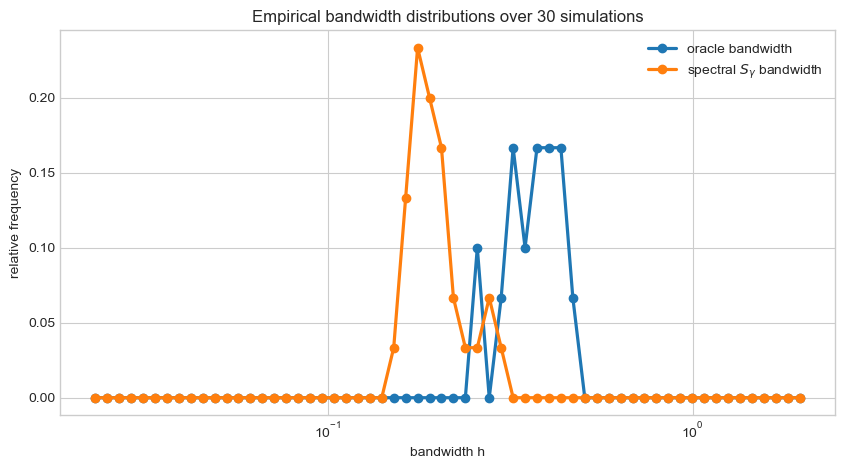

Fixed-n oracle versus spectral experiment
------------------------------------------
Data distribution: X_i ~ N(0, 1)
Sample size per simulation: n = 200
Number of simulations: R = 30
Bandwidth grid size: n_h_distribution = 60
Gamma rule: auto

Bandwidth summaries
-------------------
modal oracle h:   0.321903
modal spectral h: 0.176179
median oracle h:  0.374255
median spectral h:0.189966
mean oracle h:    0.367372
mean spectral h:  0.199708

Grid-index agreement
--------------------
Exact same grid index: 0.00%
Within 1 grid step:   0.00%
Within 2 grid steps:  0.00%


,seed,oracle_index,spectral_index,oracle_h,spectral_h,oracle_l2_error,spectral_l2_error,gamma
0,90000,37,26,0.374255,0.163393,0.072468,0.087993,76.181909
1,90001,39,28,0.435122,0.189966,0.068087,0.123564,48.665794
2,90002,38,27,0.403543,0.176179,0.047189,0.080251,58.241021
3,90003,34,28,0.298541,0.189966,0.054280,0.061076,67.996237
4,90004,37,26,0.374255,0.163393,0.042027,0.065395,63.992216


In [32]:
# Pilot defaults. Increase num_simulations_distribution and n_h_distribution for final runs.
n_distribution = 200
sigma2_distribution = 1.0
num_simulations_distribution = 30
n_h_distribution = 60
base_seed_distribution = 90_000
gamma_distribution = "auto"


def run_one_spectral_vs_oracle_experiment(
    seed: int,
    n: int,
    sigma2: float,
    h_grid: np.ndarray,
    gamma: float | str = "auto",
) -> dict[str, float | int]:
    rng = np.random.default_rng(seed)
    samples = rng.normal(loc=0.0, scale=np.sqrt(sigma2), size=n)

    ise_values_current = exact_oracle_ise_values(samples=samples, h_grid=h_grid, sigma2=sigma2)
    oracle_index = int(np.argmin(ise_values_current))

    spectral_current = select_spectral_bandwidth(samples=samples, h_grid=h_grid, gamma=gamma)
    spectral_index = int(spectral_current["selected_index"])

    return {
        "seed": seed,
        "oracle_index": oracle_index,
        "spectral_index": spectral_index,
        "oracle_h": float(h_grid[oracle_index]),
        "spectral_h": float(h_grid[spectral_index]),
        "oracle_l2_error": float(np.sqrt(max(ise_values_current[oracle_index], 0.0))),
        "spectral_l2_error": float(np.sqrt(max(ise_values_current[spectral_index], 0.0))),
        "gamma": float(spectral_current["gamma"]),
    }


h_grid_distribution = bandwidth_grid_for_gaussian_experiment(
    n=n_distribution,
    sigma2=sigma2_distribution,
    n_h=n_h_distribution,
)

bandwidth_distribution_results = [
    run_one_spectral_vs_oracle_experiment(
        seed=base_seed_distribution + simulation,
        n=n_distribution,
        sigma2=sigma2_distribution,
        h_grid=h_grid_distribution,
        gamma=gamma_distribution,
    )
    for simulation in range(num_simulations_distribution)
]

distribution_results = pd.DataFrame(bandwidth_distribution_results)

oracle_indices = distribution_results["oracle_index"].to_numpy(dtype=int)
spectral_indices = distribution_results["spectral_index"].to_numpy(dtype=int)

oracle_relative_frequencies = np.bincount(
    oracle_indices,
    minlength=len(h_grid_distribution),
) / num_simulations_distribution
spectral_relative_frequencies = np.bincount(
    spectral_indices,
    minlength=len(h_grid_distribution),
) / num_simulations_distribution

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    h_grid_distribution,
    oracle_relative_frequencies,
    marker="o",
    lw=2.3,
    label="oracle bandwidth",
)
ax.plot(
    h_grid_distribution,
    spectral_relative_frequencies,
    marker="o",
    lw=2.3,
    label=r"spectral $S_\gamma$ bandwidth",
)
ax.set_xscale("log")
ax.set_title(f"Empirical bandwidth distributions over {num_simulations_distribution} simulations")
ax.set_xlabel("bandwidth h")
ax.set_ylabel("relative frequency")
ax.legend()
plt.show()

exact_match_rate = np.mean(spectral_indices == oracle_indices)
within_1_rate = np.mean(np.abs(spectral_indices - oracle_indices) <= 1)
within_2_rate = np.mean(np.abs(spectral_indices - oracle_indices) <= 2)

print("Fixed-n oracle versus spectral experiment")
print("------------------------------------------")
print(f"Data distribution: X_i ~ N(0, {sigma2_distribution:g})")
print(f"Sample size per simulation: n = {n_distribution}")
print(f"Number of simulations: R = {num_simulations_distribution}")
print(f"Bandwidth grid size: n_h_distribution = {n_h_distribution}")
print(f"Gamma rule: {gamma_distribution}")
print()
print("Bandwidth summaries")
print("-------------------")
print(f"modal oracle h:   {h_grid_distribution[int(np.argmax(oracle_relative_frequencies))]:.6g}")
print(f"modal spectral h: {h_grid_distribution[int(np.argmax(spectral_relative_frequencies))]:.6g}")
print(f"median oracle h:  {distribution_results['oracle_h'].median():.6g}")
print(f"median spectral h:{distribution_results['spectral_h'].median():.6g}")
print(f"mean oracle h:    {distribution_results['oracle_h'].mean():.6g}")
print(f"mean spectral h:  {distribution_results['spectral_h'].mean():.6g}")
print()
print("Grid-index agreement")
print("--------------------")
print(f"Exact same grid index: {exact_match_rate:.2%}")
print(f"Within 1 grid step:   {within_1_rate:.2%}")
print(f"Within 2 grid steps:  {within_2_rate:.2%}")

distribution_results.head()


## Consistency analysis across sample sizes

For $n=50,100,150,\dots,1000$, this block repeats the oracle and spectral selections and plots
the full observed range across simulations. The shaded bands are bounded by the minimum and maximum
values over repetitions for each sample size.

## Notes

- The only data-generating model in this notebook is $N(0,\sigma^2)$.
- The comparison target is the exact oracle bandwidth on the same finite grid, not Silverman's rule.
- `gamma="auto"` rescales each sample's distance matrix so the median positive distance maps to $e^{-1}$.
  Replace it by a fixed number to study sensitivity to the monotone transform.
- The repeated-bandwidth distribution plot intentionally mirrors the earlier KDE notebook: relative
  frequencies over bandwidth grid points, with oracle and spectral choices shown as two curves.

## Extended consistency analysis: n = 100, 200, ..., 2000

This repeats the same min-max consistency analysis on the coarser sample-size grid
$n=100,200,\dots,2000$ and adds the JS quadrature selector from the earlier KDE notebook.

## KDEs selected by different similarity rules

This block draws the KDEs selected by the rules currently considered in the notebook:

- exact oracle ISE;
- JS quadrature;
- $S_\gamma(f,g)=\exp(-\gamma\|f-g\|_2^2)$;
- TV overlap $1-d_{TV}(f,g)=\int \min\{f,g\}$;
- Hellinger affinity $1-d_H(f,g)=\int \sqrt{fg}$.

The TV and Hellinger matrices are computed on the same quadrature grid as the JS matrix.

### One-sample comparison: selected bandwidths, Perron vectors, and selected KDEs

This block applies the five bandwidth choices on one simulated sample from $N(0,\sigma^2)$.

The oracle method is included as a benchmark. It is not a spectral method, because it uses the true density and minimizes

$$
\operatorname{ISE}(h_i)=\int\left(\hat f_{h_i}(x)-f(x)\right)^2\,dx.
$$

Therefore the oracle has no Perron vector. For the oracle panel below, the notebook plots the ISE curve instead.
For the four genuine spectral similarity matrices, the plotted vector is the Perron vector of the corresponding similarity matrix.

The four spectral choices are
$S^{TV}$, $S^H$, $S^\gamma$, and $S^{JS}$, as defined above.

In [ ]:
# One-sample comparison settings.
n_one_sample = 200
sigma2_one_sample = 1.0
seed_one_sample = 12345
n_h_one_sample = 80
m_x_one_sample = 2_001
gamma_one_sample = "auto"

rng = np.random.default_rng(seed_one_sample)
samples_one_sample = rng.normal(
    loc=0.0,
    scale=np.sqrt(sigma2_one_sample),
    size=n_one_sample,
)

h_grid_one_sample = bandwidth_grid_for_gaussian_experiment(
    n=n_one_sample,
    sigma2=sigma2_one_sample,
    n_h=n_h_one_sample,
)

x_grid_one_sample = quadrature_grid_for_kdes(
    samples=samples_one_sample,
    h_grid=h_grid_one_sample,
    sigma2=sigma2_one_sample,
    m_x=m_x_one_sample,
)

density_values_one_sample = gaussian_kde_values(
    samples=samples_one_sample,
    h_grid=h_grid_one_sample,
    x_grid=x_grid_one_sample,
)
density_values_one_sample = normalize_density_rows(density_values_one_sample, x_grid_one_sample)

similarity_results_one_sample = quadrature_similarity_matrices(
    density_values=density_values_one_sample,
    x_grid=x_grid_one_sample,
    gamma=gamma_one_sample,
    renormalize=False,
)

oracle_ise_one_sample = exact_oracle_ise_values(
    samples=samples_one_sample,
    h_grid=h_grid_one_sample,
    sigma2=sigma2_one_sample,
)
oracle_index_one_sample = int(np.argmin(oracle_ise_one_sample))

spectral_method_specs = [
    ("TV overlap", "tv_overlap"),
    ("Hellinger affinity", "hellinger_affinity"),
    (r"$S_\gamma$ from $L^2$", "rbf_l2"),
    ("JS similarity", "js_similarity"),
]

spectral_choices_one_sample = {}
for display_name, matrix_key in spectral_method_specs:
    choice = spectral_choice_from_similarity(similarity_results_one_sample[matrix_key])
    spectral_choices_one_sample[matrix_key] = {
        "display_name": display_name,
        "selected_index": int(choice["selected_index"]),
        "selected_h": float(h_grid_one_sample[int(choice["selected_index"])]),
        "perron_vector": choice["perron_vector"],
    }

true_density_one_sample = np.exp(-x_grid_one_sample**2 / (2 * sigma2_one_sample))
true_density_one_sample /= np.sqrt(2 * np.pi * sigma2_one_sample)

summary_rows_one_sample = [
    {
        "method": "Oracle ISE",
        "selected_index": oracle_index_one_sample,
        "selected_h": float(h_grid_one_sample[oracle_index_one_sample]),
        "uses_true_density": True,
        "has_perron_vector": False,
    }
]
for matrix_key in ["tv_overlap", "hellinger_affinity", "rbf_l2", "js_similarity"]:
    choice = spectral_choices_one_sample[matrix_key]
    summary_rows_one_sample.append(
        {
            "method": choice["display_name"],
            "selected_index": choice["selected_index"],
            "selected_h": choice["selected_h"],
            "uses_true_density": False,
            "has_perron_vector": True,
        }
    )

summary_one_sample = pd.DataFrame(summary_rows_one_sample)
print(f"Data: X_i ~ N(0, {sigma2_one_sample:g}), n = {n_one_sample}")
print(f"Bandwidth grid size: N_h = {n_h_one_sample}")
print(f"Quadrature grid size: M_x = {m_x_one_sample}")
print(f"Auto gamma used for S_gamma: {similarity_results_one_sample['gamma']:.6g}")
summary_one_sample


### Criterion curve and Perron vectors

The first panel shows the oracle ISE curve, where smaller is better.
The remaining four panels show the Perron vectors of the similarity matrices, where the selected bandwidth is the maximizer.

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharex=True)

axes[0].plot(h_grid_one_sample, oracle_ise_one_sample, marker="o", lw=2)
axes[0].axvline(h_grid_one_sample[oracle_index_one_sample], color="crimson", ls="--", lw=2)
axes[0].set_title("Oracle ISE\nlower is better")
axes[0].set_ylabel(r"$\operatorname{ISE}(h)$")

for ax, (display_name, matrix_key) in zip(axes[1:], spectral_method_specs):
    choice = spectral_choices_one_sample[matrix_key]
    vector = choice["perron_vector"]
    selected_index = choice["selected_index"]
    ax.plot(h_grid_one_sample, vector, marker="o", lw=2)
    ax.axvline(h_grid_one_sample[selected_index], color="crimson", ls="--", lw=2)
    ax.set_title(f"{display_name}\nPerron vector")
    ax.set_ylabel("Perron weight")

for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("bandwidth h")

fig.suptitle("Oracle criterion and spectral Perron-vector choices", y=1.05, fontsize=15)
plt.tight_layout()
plt.show()


### KDE at the selected bandwidth

Each panel shows the true density $N(0,\sigma^2)$ together with the KDE selected by the corresponding rule.

In [ ]:
selected_kde_specs_one_sample = [
    ("Oracle ISE", oracle_index_one_sample),
] + [
    (spectral_choices_one_sample[matrix_key]["display_name"], spectral_choices_one_sample[matrix_key]["selected_index"])
    for _, matrix_key in spectral_method_specs
]

fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharey=True)

for ax, (display_name, selected_index) in zip(axes, selected_kde_specs_one_sample):
    selected_h = h_grid_one_sample[selected_index]
    selected_kde = density_values_one_sample[selected_index]
    ax.plot(x_grid_one_sample, true_density_one_sample, color="black", lw=2.5, label="true density")
    ax.plot(x_grid_one_sample, selected_kde, lw=2.2, label="selected KDE")
    ax.set_title(f"{display_name}\nh = {selected_h:.4g}")
    ax.set_xlabel("x")
    ax.set_xlim(np.quantile(samples_one_sample, 0.005) - 1.5, np.quantile(samples_one_sample, 0.995) + 1.5)

axes[0].set_ylabel("density")
axes[0].legend(loc="upper right")
fig.suptitle("KDEs selected by the five bandwidth rules", y=1.05, fontsize=15)
plt.tight_layout()
plt.show()


## Empirical bandwidth distributions for all five rules

This repeats the bandwidth-selection experiment over 100 independent samples and plots the empirical
distribution of selected bandwidths for all five rules on the same bandwidth grid.

In [ ]:
# Empirical bandwidth distribution settings.
# Increase n_h_distribution_all5 or m_x_distribution_all5 for finer numerical resolution.
# Decrease num_simulations_distribution_all5 for a quick test run.
n_distribution_all5 = 200
sigma2_distribution_all5 = 1.0
num_simulations_distribution_all5 = 100
n_h_distribution_all5 = 80
m_x_distribution_all5 = 2_001
base_seed_distribution_all5 = 202_600
gamma_distribution_all5 = "auto"


def run_one_all5_bandwidth_experiment(
    seed: int,
    n: int,
    sigma2: float,
    h_grid: np.ndarray,
    m_x: int,
    gamma: float | str = "auto",
) -> dict[str, float | int]:
    """One repetition: oracle plus the four spectral similarity selectors."""
    rng = np.random.default_rng(seed)
    samples = rng.normal(loc=0.0, scale=np.sqrt(sigma2), size=n)

    oracle_ise = exact_oracle_ise_values(samples=samples, h_grid=h_grid, sigma2=sigma2)
    oracle_index = int(np.argmin(oracle_ise))

    x_grid = quadrature_grid_for_kdes(
        samples=samples,
        h_grid=h_grid,
        sigma2=sigma2,
        m_x=m_x,
    )
    density_values = gaussian_kde_values(samples=samples, h_grid=h_grid, x_grid=x_grid)
    density_values = normalize_density_rows(density_values, x_grid)

    similarities = quadrature_similarity_matrices(
        density_values=density_values,
        x_grid=x_grid,
        gamma=gamma,
        renormalize=False,
    )

    tv_choice = spectral_choice_from_similarity(similarities["tv_overlap"])
    hellinger_choice = spectral_choice_from_similarity(similarities["hellinger_affinity"])
    rbf_choice = spectral_choice_from_similarity(similarities["rbf_l2"])
    js_choice = spectral_choice_from_similarity(similarities["js_similarity"])

    return {
        "seed": seed,
        "oracle_index": oracle_index,
        "tv_index": int(tv_choice["selected_index"]),
        "hellinger_index": int(hellinger_choice["selected_index"]),
        "rbf_l2_index": int(rbf_choice["selected_index"]),
        "js_index": int(js_choice["selected_index"]),
        "oracle_h": float(h_grid[oracle_index]),
        "tv_h": float(h_grid[int(tv_choice["selected_index"])]),
        "hellinger_h": float(h_grid[int(hellinger_choice["selected_index"])]),
        "rbf_l2_h": float(h_grid[int(rbf_choice["selected_index"])]),
        "js_h": float(h_grid[int(js_choice["selected_index"])]),
        "oracle_l2_error": float(np.sqrt(max(oracle_ise[oracle_index], 0.0))),
        "tv_l2_error": float(np.sqrt(max(oracle_ise[int(tv_choice["selected_index"])], 0.0))),
        "hellinger_l2_error": float(np.sqrt(max(oracle_ise[int(hellinger_choice["selected_index"])], 0.0))),
        "rbf_l2_error": float(np.sqrt(max(oracle_ise[int(rbf_choice["selected_index"])], 0.0))),
        "js_l2_error": float(np.sqrt(max(oracle_ise[int(js_choice["selected_index"])], 0.0))),
        "gamma": float(similarities["gamma"]),
    }


h_grid_distribution_all5 = bandwidth_grid_for_gaussian_experiment(
    n=n_distribution_all5,
    sigma2=sigma2_distribution_all5,
    n_h=n_h_distribution_all5,
)

all5_distribution_results = pd.DataFrame(
    [
        run_one_all5_bandwidth_experiment(
            seed=base_seed_distribution_all5 + simulation,
            n=n_distribution_all5,
            sigma2=sigma2_distribution_all5,
            h_grid=h_grid_distribution_all5,
            m_x=m_x_distribution_all5,
            gamma=gamma_distribution_all5,
        )
        for simulation in range(num_simulations_distribution_all5)
    ]
)

distribution_method_specs_all5 = [
    ("Oracle ISE", "oracle_index", "oracle_h"),
    ("TV overlap", "tv_index", "tv_h"),
    ("Hellinger affinity", "hellinger_index", "hellinger_h"),
    (r"$S_\gamma$ from $L^2$", "rbf_l2_index", "rbf_l2_h"),
    ("JS similarity", "js_index", "js_h"),
]

fig, ax = plt.subplots(figsize=(11, 5.5))

frequency_rows_all5 = []
summary_rows_all5 = []

for display_name, index_key, h_key in distribution_method_specs_all5:
    selected_indices = all5_distribution_results[index_key].to_numpy(dtype=int)
    relative_frequencies = np.bincount(
        selected_indices,
        minlength=len(h_grid_distribution_all5),
    ) / num_simulations_distribution_all5

    ax.plot(
        h_grid_distribution_all5,
        relative_frequencies,
        marker="o",
        lw=2.2,
        label=display_name,
    )

    for h_value, frequency in zip(h_grid_distribution_all5, relative_frequencies):
        if frequency > 0:
            frequency_rows_all5.append(
                {
                    "method": display_name,
                    "h": float(h_value),
                    "relative_frequency": float(frequency),
                }
            )

    modal_index = int(np.argmax(relative_frequencies))
    summary_rows_all5.append(
        {
            "method": display_name,
            "modal_h": float(h_grid_distribution_all5[modal_index]),
            "modal_relative_frequency": float(relative_frequencies[modal_index]),
            "median_h": float(all5_distribution_results[h_key].median()),
            "mean_h": float(all5_distribution_results[h_key].mean()),
        }
    )

ax.set_xscale("log")
ax.set_title(
    f"Empirical bandwidth distributions over {num_simulations_distribution_all5} simulations"
)
ax.set_xlabel("bandwidth h")
ax.set_ylabel("relative frequency")
ax.legend()
plt.show()

all5_frequency_table = pd.DataFrame(frequency_rows_all5)
all5_summary_table = pd.DataFrame(summary_rows_all5)

print("Empirical bandwidth distribution experiment")
print("-------------------------------------------")
print(f"Data distribution: X_i ~ N(0, {sigma2_distribution_all5:g})")
print(f"Sample size per simulation: n = {n_distribution_all5}")
print(f"Number of simulations: R = {num_simulations_distribution_all5}")
print(f"Bandwidth grid size: N_h = {n_h_distribution_all5}")
print(f"Quadrature grid size: M_x = {m_x_distribution_all5}")
print(f"Gamma rule: {gamma_distribution_all5}")
print()
all5_summary_table


## Consistency plot: sample size versus squared integrated error

This experiment studies whether the KDE selected by a bandwidth rule improves as the sample size grows.
For each sample size

$$
n=100,200,\dots,1000,
$$

we draw several independent samples from $N(0,\sigma^2)$.
For each sample we choose one bandwidth using

- the oracle ISE rule,
- the Hellinger-affinity spectral rule,
- the JS-similarity spectral rule.

The plotted quantity is the squared integrated error

$$
\lVert \hat f_{\hat h}-f\rVert_2^2
=\int \left(\hat f_{\hat h}(x)-f(x)\right)^2\,dx.
$$

Because the true density and the kernel are Gaussian in this notebook, this error is evaluated by the exact Gaussian formula.
The spectral choices themselves are still computed from the quadrature-based Hellinger and JS similarity matrices.

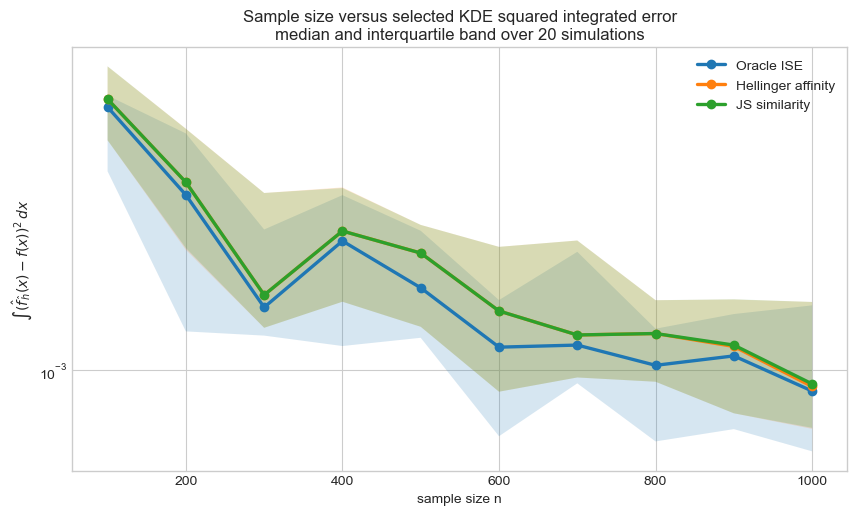

,method,n,median_squared_integrated_error,q25_squared_integrated_error,q75_squared_integrated_error,median_selected_h
0,Hellinger affinity,100,0.006594,0.004951,0.008279,0.346987
1,Hellinger affinity,200,0.003696,0.002309,0.005367,0.314091
2,Hellinger affinity,300,0.001685,0.001341,0.003430,0.289626
3,Hellinger affinity,400,0.002631,0.001608,0.003565,0.273432
4,Hellinger affinity,500,0.002257,0.001351,0.002746,0.261498
5,Hellinger affinity,600,0.001508,0.000859,0.002356,0.262169
6,Hellinger affinity,700,0.001276,0.000949,0.002463,0.244479
7,Hellinger affinity,800,0.001288,0.000921,0.001625,0.238037
8,Hellinger affinity,900,0.001178,0.000739,0.001633,0.237121
9,Hellinger affinity,1000,0.000891,0.000663,0.001605,0.227647


In [11]:
# Consistency experiment settings.
# Runtime is roughly proportional to
# len(n_values_consistency_good) * num_simulations_consistency_good * n_h_consistency_good^2 * m_x_consistency_good.
n_values_consistency_good = np.arange(100, 1001, 100)
sigma2_consistency_good = 1.0
num_simulations_consistency_good = 20
n_h_consistency_good = 60
m_x_consistency_good = 1_501
base_seed_consistency_good = 303_000
gamma_consistency_good = "auto"


def run_one_consistency_good_experiment(
    seed: int,
    n: int,
    sigma2: float,
    n_h: int,
    m_x: int,
    gamma: float | str = "auto",
) -> list[dict[str, float | int | str]]:
    """One repetition for oracle, Hellinger affinity, and JS similarity."""
    rng = np.random.default_rng(seed)
    samples = rng.normal(loc=0.0, scale=np.sqrt(sigma2), size=n)

    h_grid = bandwidth_grid_for_gaussian_experiment(n=n, sigma2=sigma2, n_h=n_h)
    ise_values = exact_oracle_ise_values(samples=samples, h_grid=h_grid, sigma2=sigma2)
    oracle_index = int(np.argmin(ise_values))

    x_grid = quadrature_grid_for_kdes(
        samples=samples,
        h_grid=h_grid,
        sigma2=sigma2,
        m_x=m_x,
    )
    density_values = gaussian_kde_values(samples=samples, h_grid=h_grid, x_grid=x_grid)
    density_values = normalize_density_rows(density_values, x_grid)

    similarities = quadrature_similarity_matrices(
        density_values=density_values,
        x_grid=x_grid,
        gamma=gamma,
        renormalize=False,
    )

    hellinger_index = int(
        spectral_choice_from_similarity(similarities["hellinger_affinity"])["selected_index"]
    )
    js_index = int(
        spectral_choice_from_similarity(similarities["js_similarity"])["selected_index"]
    )

    return [
        {
            "n": int(n),
            "seed": int(seed),
            "method": "Oracle ISE",
            "selected_index": oracle_index,
            "selected_h": float(h_grid[oracle_index]),
            "squared_integrated_error": float(ise_values[oracle_index]),
        },
        {
            "n": int(n),
            "seed": int(seed),
            "method": "Hellinger affinity",
            "selected_index": hellinger_index,
            "selected_h": float(h_grid[hellinger_index]),
            "squared_integrated_error": float(ise_values[hellinger_index]),
        },
        {
            "n": int(n),
            "seed": int(seed),
            "method": "JS similarity",
            "selected_index": js_index,
            "selected_h": float(h_grid[js_index]),
            "squared_integrated_error": float(ise_values[js_index]),
        },
    ]


consistency_good_rows = []

for n_current in n_values_consistency_good:
    for simulation in range(num_simulations_consistency_good):
        seed = base_seed_consistency_good + 10_000 * int(n_current) + simulation
        consistency_good_rows.extend(
            run_one_consistency_good_experiment(
                seed=seed,
                n=int(n_current),
                sigma2=sigma2_consistency_good,
                n_h=n_h_consistency_good,
                m_x=m_x_consistency_good,
                gamma=gamma_consistency_good,
            )
        )

consistency_good_results = pd.DataFrame(consistency_good_rows)

fig, ax = plt.subplots(figsize=(10, 5.5))

method_order_consistency_good = ["Oracle ISE", "Hellinger affinity", "JS similarity"]

for method in method_order_consistency_good:
    method_data = consistency_good_results[consistency_good_results["method"] == method]
    grouped = method_data.groupby("n")["squared_integrated_error"]
    n_plot = np.array(sorted(method_data["n"].unique()), dtype=int)
    median_error = grouped.median().loc[n_plot].to_numpy(dtype=float)
    q25_error = grouped.quantile(0.25).loc[n_plot].to_numpy(dtype=float)
    q75_error = grouped.quantile(0.75).loc[n_plot].to_numpy(dtype=float)

    ax.plot(n_plot, median_error, marker="o", lw=2.4, label=method)
    ax.fill_between(n_plot, q25_error, q75_error, alpha=0.18)

ax.set_title(
    "Sample size versus selected KDE squared integrated error\n"
    f"median and interquartile band over {num_simulations_consistency_good} simulations"
)
ax.set_xlabel("sample size n")
ax.set_ylabel(r"$\int (\hat f_{\hat h}(x)-f(x))^2\,dx$")
ax.set_yscale("log")
ax.legend()
plt.show()

consistency_good_summary = (
    consistency_good_results
    .groupby(["method", "n"])
    .agg(
        median_squared_integrated_error=("squared_integrated_error", "median"),
        q25_squared_integrated_error=("squared_integrated_error", lambda x: x.quantile(0.25)),
        q75_squared_integrated_error=("squared_integrated_error", lambda x: x.quantile(0.75)),
        median_selected_h=("selected_h", "median"),
    )
    .reset_index()
)

consistency_good_summary.head(12)
